# IMPORT LIBRARY

In [ ]:
import os
import zipfile
import cv2
import numpy as np
import matplotlib.pyplot as plt
import gdown

from glob import glob
from skimage.feature import hog, local_binary_pattern
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from google.colab import files

# DOWNLOAD DATASET

In [ ]:
!gdown 15F_h6JE8H6zaRQTuOebn9DZxRTQB4-RR

Downloading...
From (original): https://drive.google.com/uc?id=15F_h6JE8H6zaRQTuOebn9DZxRTQB4-RR
From (redirected): https://drive.google.com/uc?id=15F_h6JE8H6zaRQTuOebn9DZxRTQB4-RR&confirm=t&uuid=bda69576-f07c-4002-84be-195b8bd2f08b
To: /content/ambulance.zip
100% 93.2M/93.2M [00:01<00:00, 62.1MB/s]


# EKSTRAKSI DATASET

In [ ]:
zip_name = '/content/ambulance.zip'
extract_path = 'dataset'

if os.path.exists(zip_name):
    with zipfile.ZipFile(zip_name, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Ekstraksi Berhasil")
else:
    print(f"✗ File {zip_name} tidak ditemukan")

DATASET_PATH = ""
for root, dirs, files_in_dir in os.walk(extract_path):
    if 'ambulance' in dirs and 'noambulance' in dirs:
        DATASET_PATH = root
        break

print("Dataset Path:", DATASET_PATH)

Ekstraksi Berhasil
Dataset Path: dataset/carsdataset


# LOAD PATH GAMBAR

In [ ]:
def load_image_paths(base_path):
    """Fungsi untuk memuat path gambar ambulance dan non-ambulance"""
    ambulance = glob(os.path.join(base_path, 'ambulance', '*'))
    no_ambulance = glob(os.path.join(base_path, 'noambulance', '*'))
    return ambulance, no_ambulance

ambulance_images, no_ambulance_images = load_image_paths(DATASET_PATH)

print(f"Total Ambulance: {len(ambulance_images)}")
print(f"Total Non-Ambulance: {len(no_ambulance_images)}")
print(f"Total Dataset: {len(ambulance_images) + len(no_ambulance_images)}")

Total Ambulance: 2121
Total Non-Ambulance: 2628
Total Dataset: 4749


# VISUALISASI DATASET AWAL


VISUALISASI DATASET


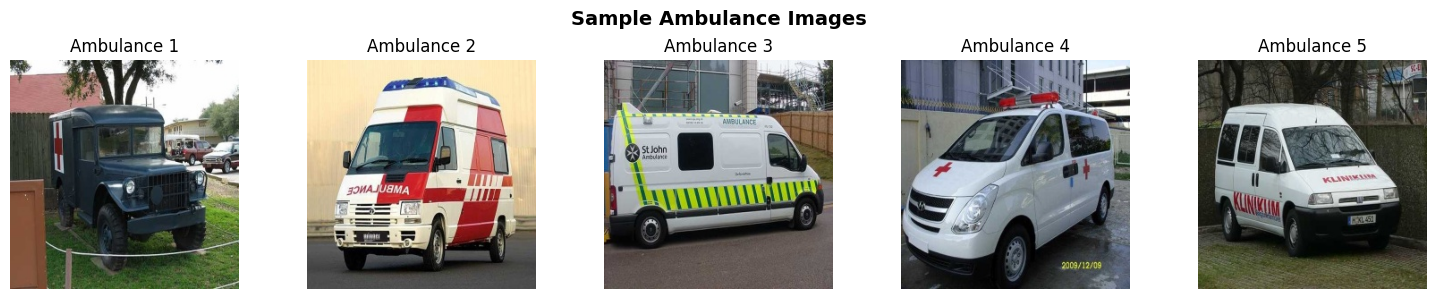

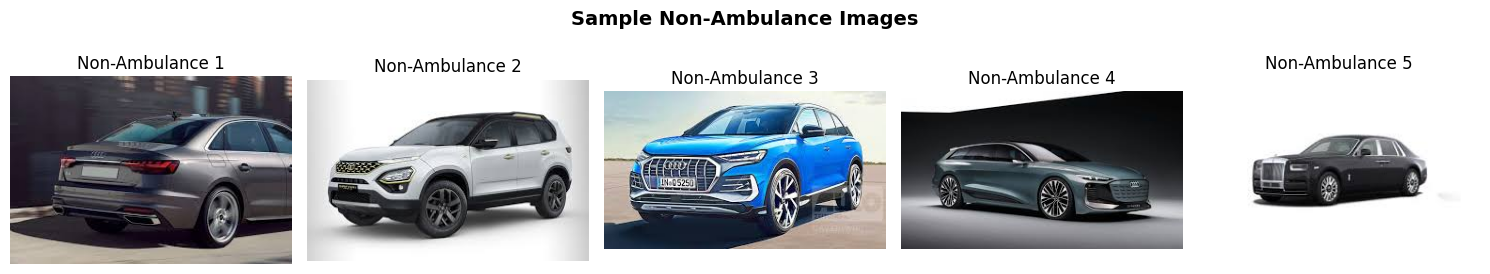

In [ ]:
def show_samples(image_list, title):
    """Menampilkan sample gambar dari dataset"""
    plt.figure(figsize=(15, 3))
    for i, img_path in enumerate(image_list[:5]):
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.subplot(1, 5, i+1)
        plt.imshow(img)
        plt.title(f"{title} {i+1}")
        plt.axis('off')
    plt.suptitle(f"Sample {title} Images", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

print("\nVISUALISASI DATASET")
show_samples(ambulance_images, "Ambulance")
show_samples(no_ambulance_images, "Non-Ambulance")

# FUNGSI EKSTRAKSI FITUR COLOR (HSV)

In [ ]:
# FUNGSI EKSTRAKSI FITUR COLOR (HSV)
# Menghasilkan histogram 4-dimensi yang tidak dapat divisualisasikan
def extract_color(image, features="all"):
    """
    Ekstraksi fitur warna menggunakan histogram HSV
    - H (Hue): Warna (merah, kuning, hijau...)
    - S (Saturation): Intensitas warna (hitam, hitam kemerahan, merah sedikit hitam, merah)
    - V (Value): Kecerahan (merah tua, merah, merah muda)
    """
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    if features == "hue":
      hist = cv2.calcHist([hsv], [0], None, [8], [0, 180])
    elif features == "saturation":
      hist = cv2.calcHist([hsv], [1], None, [8], [0, 256])
    elif features == "value":
      hist = cv2.calcHist([hsv], [2], None, [8], [0, 256])
    else:
      hist = cv2.calcHist([hsv], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256])
    cv2.normalize(hist, hist)
    return hist.flatten()

# FUNGSI EKSTRAKSI FITUR HOG

In [ ]:
# FUNGSI EKSTRAKSI FITUR HOG
def extract_hog_feature(image):
    """
    Histogram of Oriented Gradients (HOG)
    - Mendeteksi arah dan tepi objek
    - Berguna untuk mengenali struktur ambulance
    """
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return hog(gray,
               orientations=9,
               pixels_per_cell=(8, 8),
               cells_per_block=(2, 2),
               block_norm='L2-Hys')

# FUNGSI EKSTRAKSI FITUR LBP

In [ ]:
# FUNGSI EKSTRAKSI FITUR LBP
def extract_lbp_feature(image, P=24, R=3):
    """
    Local Binary Pattern (LBP)
    - Mendeteksi tekstur gambar
    - Berguna untuk mengenali pola detail pada ambulance
    """
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, P, R, method="uniform")
    hist, _ = np.histogram(lbp.ravel(),
                           bins=np.arange(0, P+3),
                           range=(0, P+2))
    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-6)
    return hist

# VISUALISASI PROSES EKSTRAKSI FITUR


 PROSES EKSTRAKSI FITUR (Contoh Ambulance)


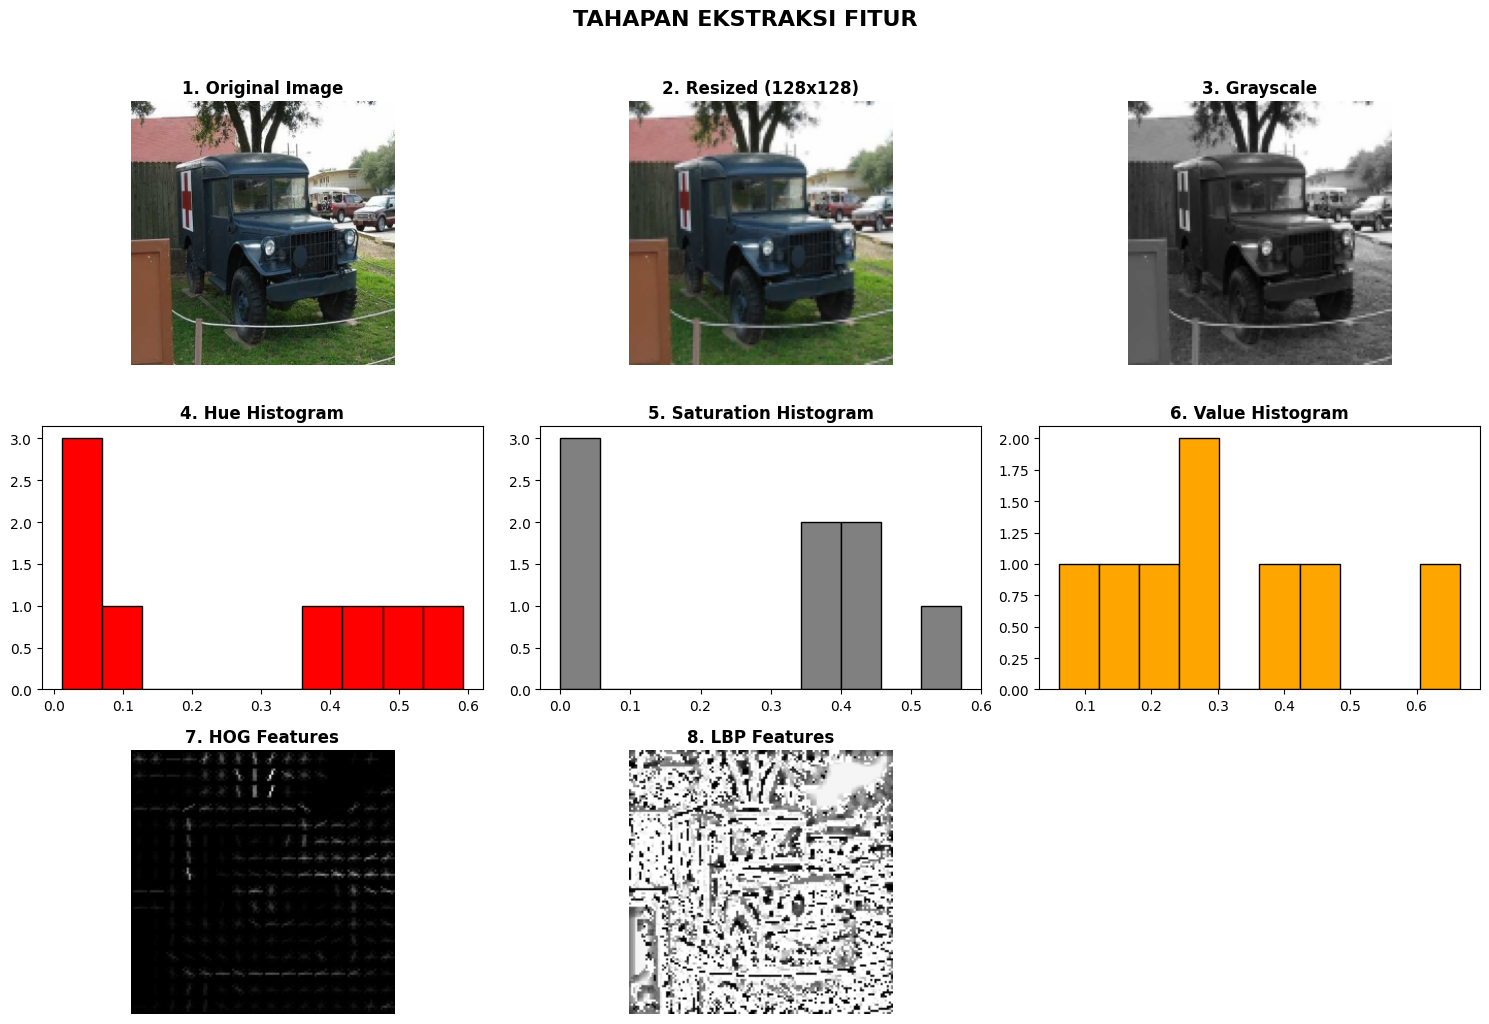


 DIMENSI FITUR YANG DIEKSTRAK: 

1. Color Histogram (HSV): 512 fitur
2. HOG Features: 8100 fitur
3. LBP Features: 26 fitur
Total Combined Features: 8638 fitur

 PROSES EKSTRAKSI FITUR (Contoh Non-Ambulance)


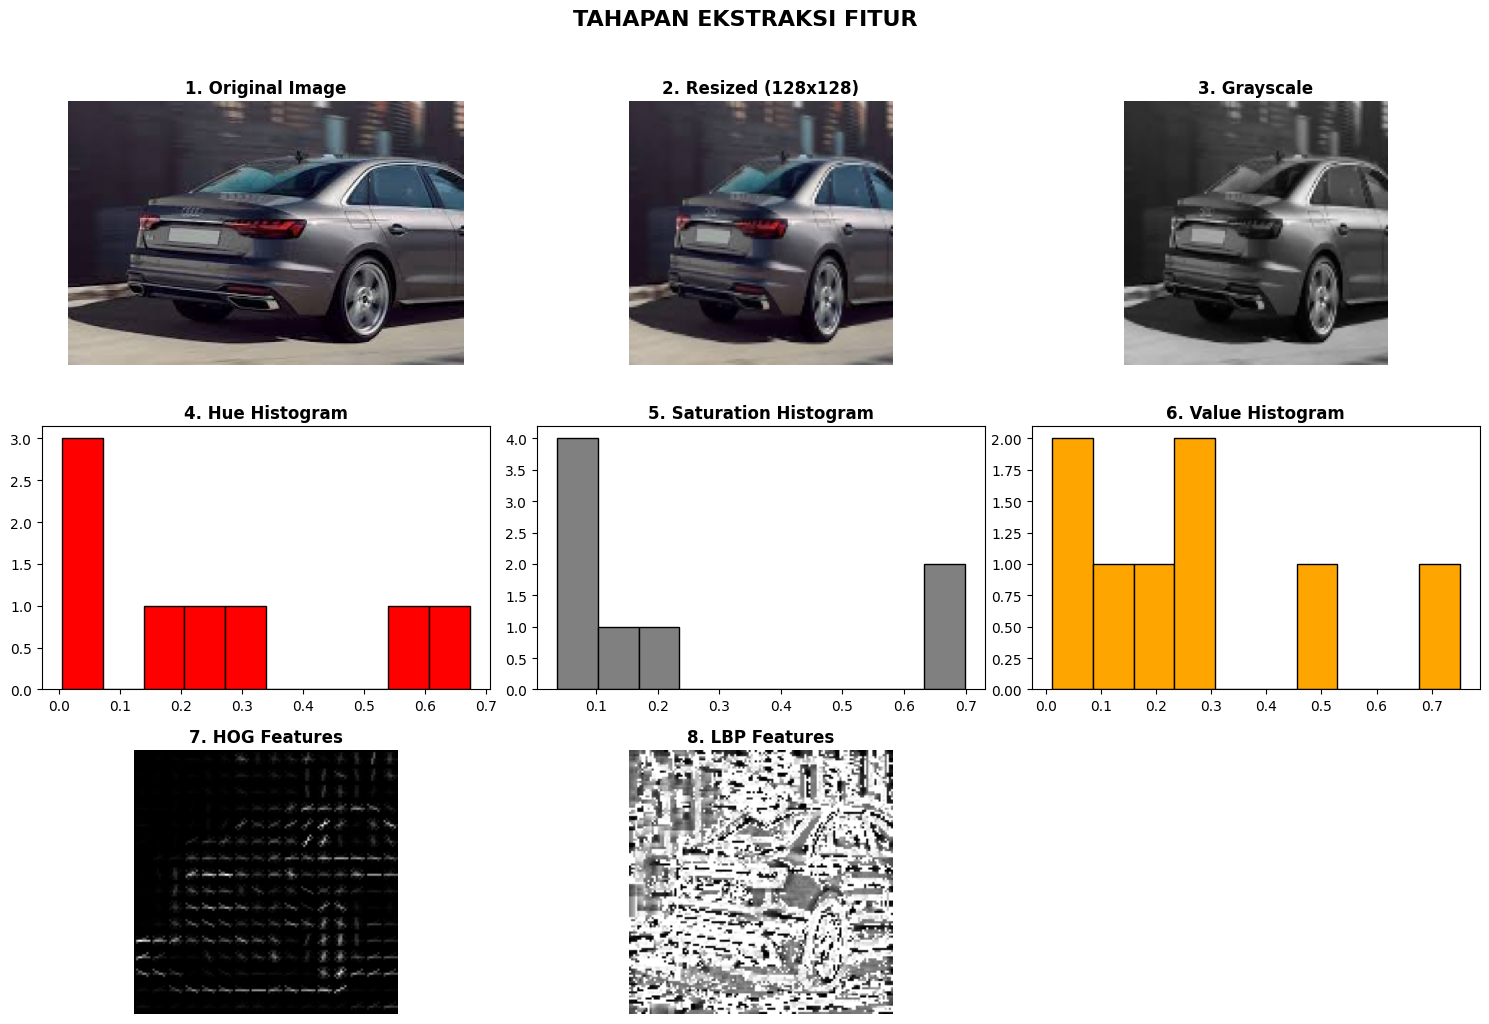


 DIMENSI FITUR YANG DIEKSTRAK: 

1. Color Histogram (HSV): 512 fitur
2. HOG Features: 8100 fitur
3. LBP Features: 26 fitur
Total Combined Features: 8638 fitur


In [ ]:
# VISUALISASI PROSES EKSTRAKSI FITUR
def visualize_feature_extraction(image_path):
    """
    Menampilkan setiap tahap ekstraksi fitur
    """
    # Baca gambar
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img, (128, 128))

    # Convert ke berbagai color space
    gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)

    # HSV dibagi menjadi tiga histogram untuk visualisasi
    hue_hist = extract_color(img_resized, "hue")
    saturation_hist = extract_color(img_resized, "saturation")
    value_hist = extract_color(img_resized, "value")

    # Ekstraksi HOG
    hog_features, hog_image = hog(gray,
                                   orientations=9,
                                   pixels_per_cell=(8, 8),
                                   cells_per_block=(2, 2),
                                   block_norm='L2-Hys',
                                   visualize=True)

    # Ekstraksi LBP
    lbp = local_binary_pattern(gray, 24, 3, method="uniform")

    # Plotting

    # Visualisasi
    fig, axes = plt.subplots(3, 3, figsize=(15, 10))

    # Original Image
    axes[0, 0].imshow(img_rgb)
    axes[0, 0].set_title('1. Original Image', fontweight='bold')
    axes[0, 0].axis('off')

    # Resized Image
    axes[0, 1].imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
    axes[0, 1].set_title('2. Resized (128x128)', fontweight='bold')
    axes[0, 1].axis('off')

    # Grayscale
    axes[0, 2].imshow(gray, cmap='gray')
    axes[0, 2].set_title('3. Grayscale', fontweight='bold')
    axes[0, 2].axis('off')

    # Hue
    axes[1, 0].hist(hue_hist, color='red', edgecolor='black')
    axes[1, 0].set_title('4. Hue Histogram', fontweight='bold')

    # Saturation
    axes[1, 1].hist(saturation_hist, color='gray', edgecolor='black')
    axes[1, 1].set_title('5. Saturation Histogram', fontweight='bold')

    # Value
    axes[1, 2].hist(value_hist, color='orange', edgecolor='black')
    axes[1, 2].set_title('6. Value Histogram', fontweight='bold')

    # HOG
    axes[2, 0].imshow(hog_image, cmap='gray')
    axes[2, 0].set_title('7. HOG Features', fontweight='bold')
    axes[2, 0].axis('off')

    # LBP
    axes[2, 1].imshow(lbp, cmap='gray')
    axes[2, 1].set_title('8. LBP Features', fontweight='bold')
    axes[2, 1].axis('off')

    axes[2, 2].axis('off')

    plt.suptitle('TAHAPAN EKSTRAKSI FITUR', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

    # Tampilkan dimensi fitur
    print("\n DIMENSI FITUR YANG DIEKSTRAK: \n")
    color_feat = extract_color(img_resized)
    hog_feat = extract_hog_feature(img_resized)
    lbp_feat = extract_lbp_feature(img_resized)

    print(f"1. Color Histogram (HSV): {len(color_feat)} fitur")
    print(f"2. HOG Features: {len(hog_feat)} fitur")
    print(f"3. LBP Features: {len(lbp_feat)} fitur")
    print(f"Total Combined Features: {len(color_feat) + len(hog_feat) + len(lbp_feat)} fitur")

# Tampilkan proses ekstraksi fitur untuk 1 contoh gambar ambulance
print("\n PROSES EKSTRAKSI FITUR (Contoh Ambulance)")
visualize_feature_extraction(ambulance_images[0])

print("\n PROSES EKSTRAKSI FITUR (Contoh Non-Ambulance)")
visualize_feature_extraction(no_ambulance_images[0])

# EKSTRAKSI FITUR SELURUH DATASET


 Memproses gambar Ambulance...
  Processed 500/2121 ambulance images...
  Processed 1000/2121 ambulance images...
  Processed 1500/2121 ambulance images...
  Processed 2000/2121 ambulance images...

 Memproses gambar Non-Ambulance...
  Processed 500/2628 noambulance images...
  Processed 1000/2628 noambulance images...
  Processed 1500/2628 noambulance images...
  Processed 2000/2628 noambulance images...
  Processed 2500/2628 noambulance images...

 HASIL EKSTRAKSI FITUR:

Shape X (Features): (4749, 8638)
Shape y (Labels): (4749,)
Total Samples: 4749
Total Features per Sample: 8638


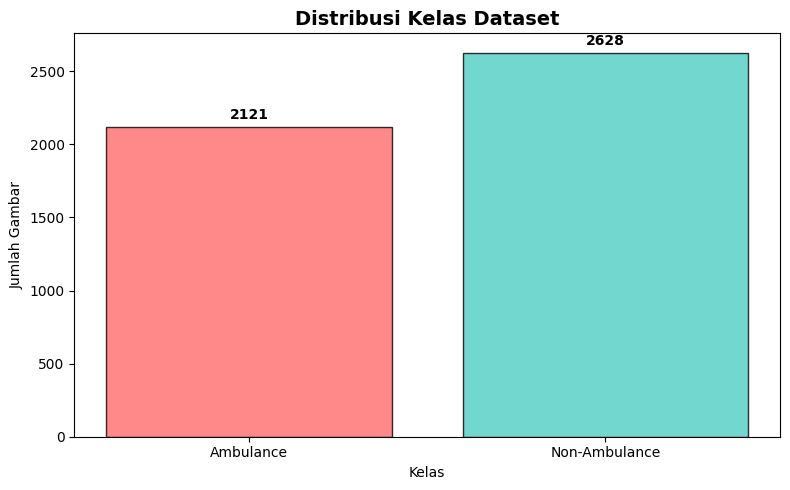

In [ ]:
# EKSTRAKSI FITUR SELURUH DATASET
IMG_SIZE = (128, 128)
X = []
y = []

def process_images(image_paths, label):
    """Proses ekstraksi fitur untuk semua gambar"""
    for idx, path in enumerate(image_paths):
        img = cv2.imread(path)
        if img is None:
            continue
        img = cv2.resize(img, IMG_SIZE)

        # Ekstraksi 3 jenis fitur
        color = extract_color(img)
        hog_f = extract_hog_feature(img)
        lbp_f = extract_lbp_feature(img)

        # Gabungkan semua fitur
        features = np.hstack([color, hog_f, lbp_f])
        X.append(features)
        y.append(label)

        # Progress indicator
        if (idx + 1) % 500 == 0:
            print(f"  Processed {idx + 1}/{len(image_paths)} {label} images...")

print("\n Memproses gambar Ambulance...")
process_images(ambulance_images, "ambulance")

print("\n Memproses gambar Non-Ambulance...")
process_images(no_ambulance_images, "noambulance")

# Konversi ke numpy array dan encode label
X = np.array(X)
y = LabelEncoder().fit_transform(y)

print("\n HASIL EKSTRAKSI FITUR:\n")
print(f"Shape X (Features): {X.shape}")
print(f"Shape y (Labels): {y.shape}")
print(f"Total Samples: {X.shape[0]}")
print(f"Total Features per Sample: {X.shape[1]}")

# Visualisasi distribusi kelas
plt.figure(figsize=(8, 5))
labels, counts = np.unique(y, return_counts=True)
label_names = ['Ambulance', 'Non-Ambulance']
colors = ['#FF6B6B', '#4ECDC4']
plt.bar(label_names, counts, color=colors, alpha=0.8, edgecolor='black')
plt.title('Distribusi Kelas Dataset', fontsize=14, fontweight='bold')
plt.ylabel('Jumlah Gambar')
plt.xlabel('Kelas')
for i, count in enumerate(counts):
    plt.text(i, count + 50, str(count), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

# SPLIT DATA DAN NORMALISASI

DATA SPLIT:

Training Set: 3799 samples (80.0%)
Testing Set: 950 samples (20.0%)

 Normalisasi fitur dengan StandardScaler...
Normalisasi selesai


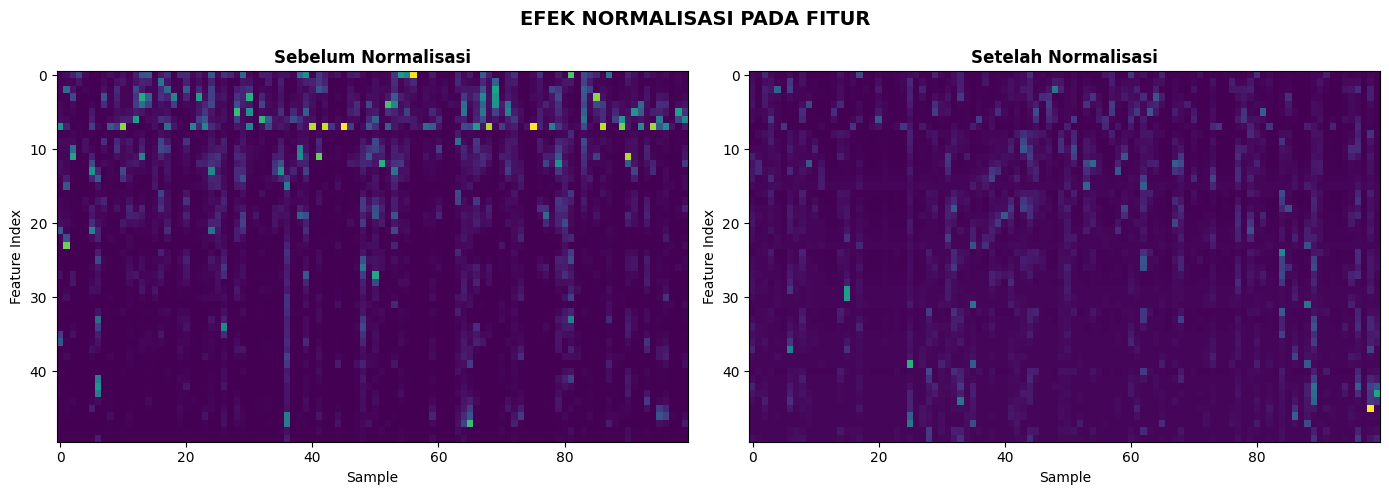

In [ ]:
# SPLIT DATA DAN NORMALISASI
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("DATA SPLIT:\n")
print(f"Training Set: {X_train.shape[0]} samples ({X_train.shape[0]/X.shape[0]*100:.1f}%)")
print(f"Testing Set: {X_test.shape[0]} samples ({X_test.shape[0]/X.shape[0]*100:.1f}%)")

print("\n Normalisasi fitur dengan StandardScaler...")
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Normalisasi selesai")

# Visualisasi perbandingan sebelum dan sesudah normalisasi
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Before normalization (gunakan sample asli)
sample_before = X[:100, :50]  # 100 samples, 50 features pertama
ax1.imshow(sample_before.T, aspect='auto', cmap='viridis')
ax1.set_title('Sebelum Normalisasi', fontweight='bold')
ax1.set_xlabel('Sample')
ax1.set_ylabel('Feature Index')
ax1.set_aspect('auto')

# After normalization
sample_after = X_train[:100, :50]
ax2.imshow(sample_after.T, aspect='auto', cmap='viridis')
ax2.set_title('Setelah Normalisasi', fontweight='bold')
ax2.set_xlabel('Sample')
ax2.set_ylabel('Feature Index')
ax2.set_aspect('auto')

plt.suptitle('EFEK NORMALISASI PADA FITUR', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# TRAINING SVM KERNEL RBF

In [ ]:
# TRAINING SVM KERNEL RBF
print("   Parameter: kernel='rbf', C=10, gamma='scale'")
model = SVC(kernel='rbf', C=10, gamma='scale')
model.fit(X_train, y_train)
print("Model SVM berhasil dilatih")

   Parameter: kernel='rbf', C=10, gamma='scale'
Model SVM berhasil dilatih


# EVALUASI MODEL


 Evaluasi model pada data testing

 ACCURACY: 93.47% 


CLASSIFICATION REPORT:
               precision    recall  f1-score   support

    Ambulance       0.94      0.91      0.93       424
Non-Ambulance       0.93      0.96      0.94       526

     accuracy                           0.93       950
    macro avg       0.94      0.93      0.93       950
 weighted avg       0.93      0.93      0.93       950



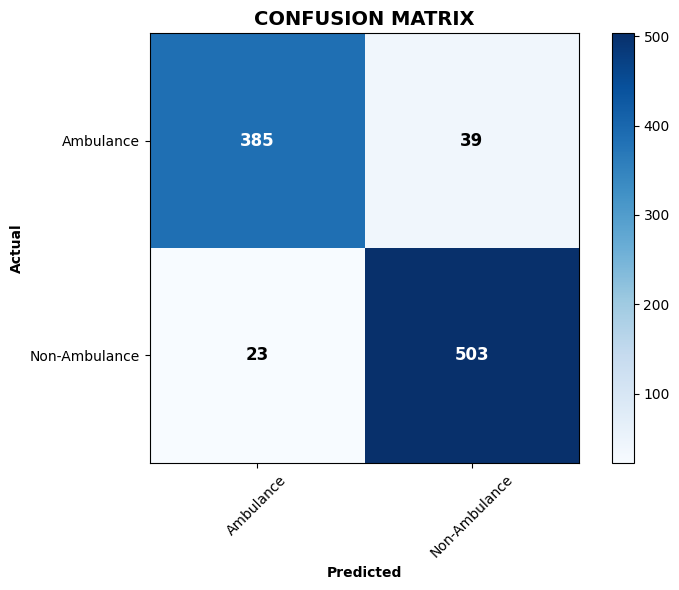

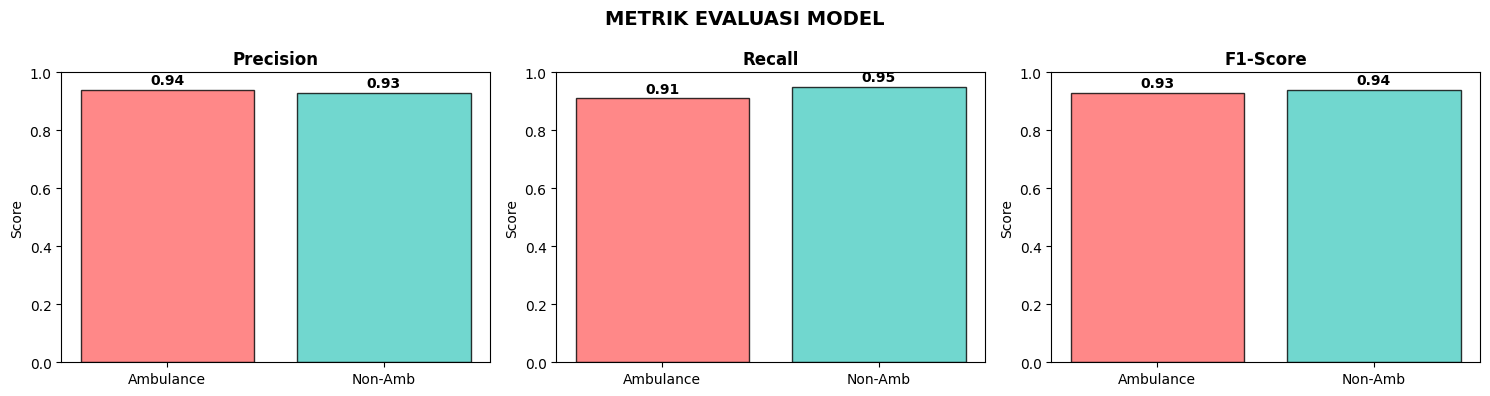

In [ ]:
# EVALUASI MODEL
print("\n Evaluasi model pada data testing")
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"\n ACCURACY: {accuracy*100:.2f}% \n")
print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred, target_names=['Ambulance', 'Non-Ambulance']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap='Blues', interpolation='nearest')
plt.title('CONFUSION MATRIX', fontsize=14, fontweight='bold')
plt.colorbar()

# Tambahkan label
classes = ['Ambulance', 'Non-Ambulance']
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

# Tambahkan nilai di setiap cell
thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black",
                fontweight='bold', fontsize=12)

plt.ylabel('Actual', fontweight='bold')
plt.xlabel('Predicted', fontweight='bold')
plt.tight_layout()
plt.show()

# Visualisasi metrik
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Precision
precision = [0.94, 0.93]  # dari classification report
axes[0].bar(['Ambulance', 'Non-Amb'], precision, color=['#FF6B6B', '#4ECDC4'], alpha=0.8, edgecolor='black')
axes[0].set_title('Precision', fontweight='bold')
axes[0].set_ylim([0, 1])
axes[0].set_ylabel('Score')
for i, v in enumerate(precision):
    axes[0].text(i, v + 0.02, f'{v:.2f}', ha='center', fontweight='bold')

# Recall
recall = [0.91, 0.95]
axes[1].bar(['Ambulance', 'Non-Amb'], recall, color=['#FF6B6B', '#4ECDC4'], alpha=0.8, edgecolor='black')
axes[1].set_title('Recall', fontweight='bold')
axes[1].set_ylim([0, 1])
axes[1].set_ylabel('Score')
for i, v in enumerate(recall):
    axes[1].text(i, v + 0.02, f'{v:.2f}', ha='center', fontweight='bold')

# F1-Score
f1 = [0.93, 0.94]
axes[2].bar(['Ambulance', 'Non-Amb'], f1, color=['#FF6B6B', '#4ECDC4'], alpha=0.8, edgecolor='black')
axes[2].set_title('F1-Score', fontweight='bold')
axes[2].set_ylim([0, 1])
axes[2].set_ylabel('Score')
for i, v in enumerate(f1):
    axes[2].text(i, v + 0.02, f'{v:.2f}', ha='center', fontweight='bold')

plt.suptitle('METRIK EVALUASI MODEL', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# PREDIKSI GAMBAR BARU

UPLOAD GAMBAR UNTUK PREDIKSI


Saving dataset-cover.jpeg to dataset-cover.jpeg

 Memproses: dataset-cover.jpeg


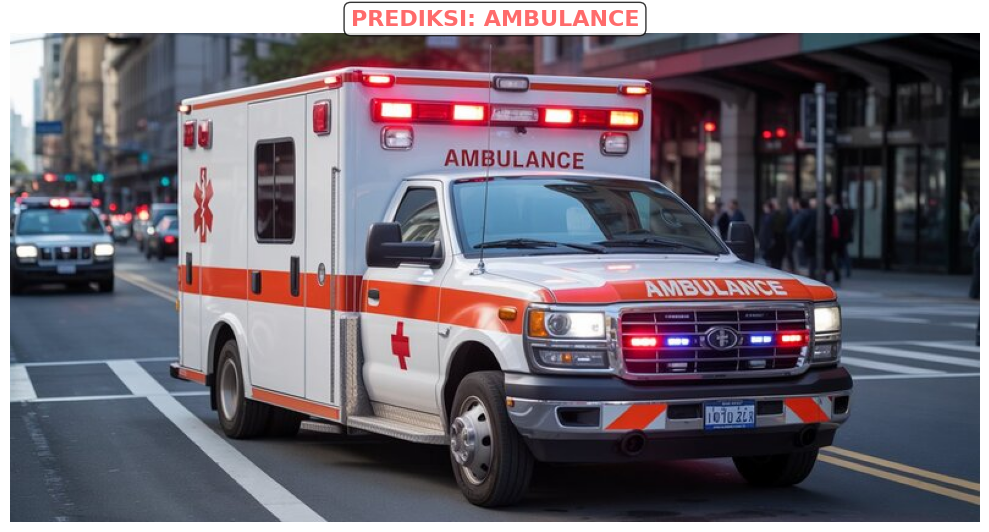

Hasil: AMBULANCE


In [ ]:
# PREDIKSI GAMBAR BARU
def predict_image(image_path):
    """
    Fungsi untuk memprediksi gambar baru
    """
    img = cv2.imread(image_path)
    img = cv2.resize(img, IMG_SIZE)

    # Ekstraksi fitur
    feat = np.hstack([
        extract_color(img),
        extract_hog_feature(img),
        extract_lbp_feature(img)
    ])

    # Normalisasi
    feat = scaler.transform([feat])

    # Prediksi
    pred = model.predict(feat)[0]

    return "AMBULANCE" if pred == 0 else "NON-AMBULANCE"

def predict_and_visualize(image_path):
    """
    Prediksi dengan visualisasi lengkap
    """
    # Prediksi
    result = predict_image(image_path)

    # Load gambar
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Visualisasi
    plt.figure(figsize=(10, 6))
    plt.imshow(img_rgb)

    # Warna berdasarkan hasil prediksi
    color = '#FF6B6B' if result == "AMBULANCE" else '#4ECDC4'
    plt.title(f'PREDIKSI: {result}', fontsize=16, fontweight='bold',
              color=color, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    return result

# Upload dan prediksi gambar baru
print("UPLOAD GAMBAR UNTUK PREDIKSI")
uploaded = files.upload()

for file in uploaded.keys():
    print(f"\n Memproses: {file}")
    result = predict_and_visualize(file)
    print(f"Hasil: {result}")

UPLOAD GAMBAR UNTUK PREDIKSI


Saving WhatsApp-Image-2021-10-13-at-2.15.03-PM-2.jpeg.webp to WhatsApp-Image-2021-10-13-at-2.15.03-PM-2.jpeg.webp

 Memproses: WhatsApp-Image-2021-10-13-at-2.15.03-PM-2.jpeg.webp


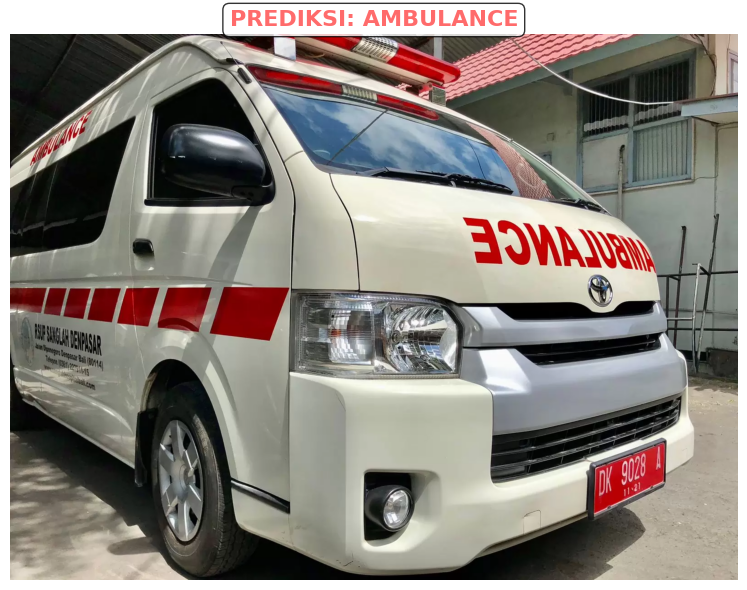

Hasil: AMBULANCE


In [ ]:
# PREDIKSI GAMBAR BARU
def predict_image(image_path):
    """
    Fungsi untuk memprediksi gambar baru
    """
    img = cv2.imread(image_path)
    img = cv2.resize(img, IMG_SIZE)

    # Ekstraksi fitur
    feat = np.hstack([
        extract_color(img),
        extract_hog_feature(img),
        extract_lbp_feature(img)
    ])

    # Normalisasi
    feat = scaler.transform([feat])

    # Prediksi
    pred = model.predict(feat)[0]

    return "AMBULANCE" if pred == 0 else "NON-AMBULANCE"

def predict_and_visualize(image_path):
    """
    Prediksi dengan visualisasi lengkap
    """
    # Prediksi
    result = predict_image(image_path)

    # Load gambar
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Visualisasi
    plt.figure(figsize=(10, 6))
    plt.imshow(img_rgb)

    # Warna berdasarkan hasil prediksi
    color = '#FF6B6B' if result == "AMBULANCE" else '#4ECDC4'
    plt.title(f'PREDIKSI: {result}', fontsize=16, fontweight='bold',
              color=color, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    return result

# Upload dan prediksi gambar baru
print("UPLOAD GAMBAR UNTUK PREDIKSI")
uploaded = files.upload()

for file in uploaded.keys():
    print(f"\n Memproses: {file}")
    result = predict_and_visualize(file)
    print(f"Hasil: {result}")

UPLOAD GAMBAR UNTUK PREDIKSI


Saving mobil-kecil.webp to mobil-kecil.webp

 Memproses: mobil-kecil.webp


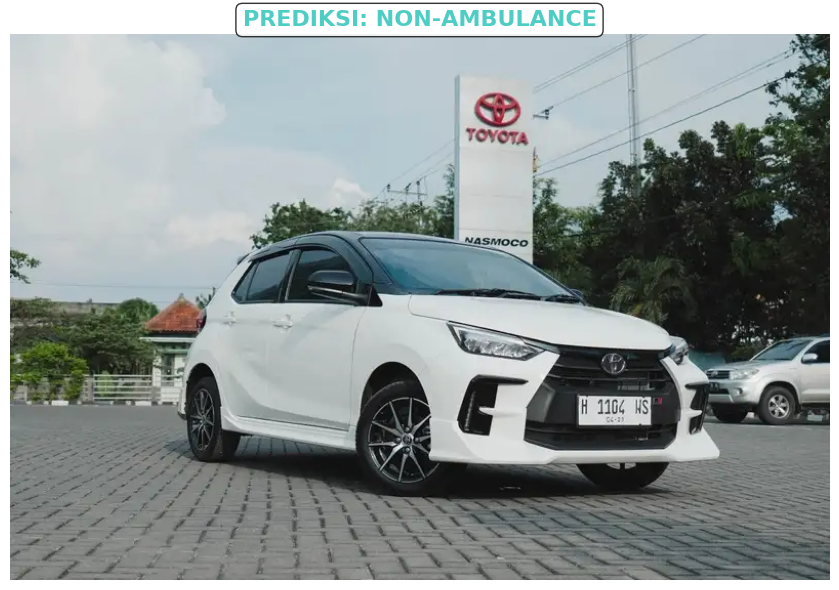

Hasil: NON-AMBULANCE


In [ ]:
# PREDIKSI GAMBAR BARU
def predict_image(image_path):
    """
    Fungsi untuk memprediksi gambar baru
    """
    img = cv2.imread(image_path)
    img = cv2.resize(img, IMG_SIZE)

    # Ekstraksi fitur
    feat = np.hstack([
        extract_color(img),
        extract_hog_feature(img),
        extract_lbp_feature(img)
    ])

    # Normalisasi
    feat = scaler.transform([feat])

    # Prediksi
    pred = model.predict(feat)[0]

    return "AMBULANCE" if pred == 0 else "NON-AMBULANCE"

def predict_and_visualize(image_path):
    """
    Prediksi dengan visualisasi lengkap
    """
    # Prediksi
    result = predict_image(image_path)

    # Load gambar
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Visualisasi
    plt.figure(figsize=(10, 6))
    plt.imshow(img_rgb)

    # Warna berdasarkan hasil prediksi
    color = '#FF6B6B' if result == "AMBULANCE" else '#4ECDC4'
    plt.title(f'PREDIKSI: {result}', fontsize=16, fontweight='bold',
              color=color, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    return result

# Upload dan prediksi gambar baru
print("UPLOAD GAMBAR UNTUK PREDIKSI")
uploaded = files.upload()

for file in uploaded.keys():
    print(f"\n Memproses: {file}")
    result = predict_and_visualize(file)
    print(f"Hasil: {result}")